In [1]:
import numpy as np
import skimage.io
import skimage.color
import skimage.filters
import skimage.transform
from skimage import img_as_ubyte
import matplotlib.pyplot as plt
import constants
import IPython.display as d
import json
import os
import time
import torch
from torchvision import transforms, utils, datasets
from torch.utils.data import Dataset, DataLoader
from torch.autograd import Variable
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import shutil
from sklearn import metrics
from PIL import Image
import json
import random
import pandas as pd
import tensorflow as tf
from keras import layers
import keras
import keras_tuner
import gc
import seaborn as sn
import pandas as pd
import matplotlib.pyplot as plt

hp = keras_tuner.HyperParameters()

print(tf.__version__)
print(tf.config.list_physical_devices())

2.10.0
[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
def test_model(model, dataset):
    filtered_data = []
    TP = 0
    FP = 0
    TN = 0
    FN = 0
    for i, (images, label) in enumerate(dataset, 0):
        output = model(images)
        prediction = output.numpy()
        for i in range(len(prediction)):
            if prediction[i][0] > 0.4:
                if label[i]== 1:
                    TP += 1
                else: FP += 1
                filtered_data.append(images[i])
                # print(prediction[i], label[i])
            else:
                if label[i]== 1:
                    FN += 1
                else: TN += 1

    f1 = (2*TP)/(2*TP+FP+FN)
    return filtered_data, TP, FP, TN, FN, f1

In [3]:
train_ds, valid_ds = keras.utils.image_dataset_from_directory(
    directory='./data/images_256_train/',
    labels='inferred',
    label_mode='binary',
    batch_size=10,
    image_size=(256,256),
    validation_split=0.2,
    subset='both',
    seed=42
)
test_ds = keras.utils.image_dataset_from_directory(
    directory='./data/images_256_test/',
    labels='inferred',
    label_mode='binary',
    batch_size=5,
    image_size=(256,256),
    seed=42
)

def process(image,label):
    image = tf.cast(image/255. ,tf.float32)
    return image,label
train_ds = train_ds.map(process)
valid_ds = valid_ds.map(process)
test_ds = test_ds.map(process)

Found 18482 files belonging to 2 classes.
Using 14786 files for training.
Using 3696 files for validation.
Found 4610 files belonging to 2 classes.


In [4]:
# model128 = keras.models.load_model('./trained_models/model128/')
# model128.trainable=False

model = keras.models.Sequential()
# Correct model
model.add(keras.Input(shape=(256,256,3)))

model.add(layers.Conv2D(filters=32, kernel_size=7, strides=2, activation='relu', padding='same'))
model.add(layers.MaxPool2D(pool_size=2, strides=2))

model.add(layers.Conv2D(filters=64,kernel_size=3, strides=2, activation='relu', padding='same'))
model.add(layers.Conv2D(filters=64,kernel_size=3, activation='relu', padding='same'))
model.add(layers.MaxPool2D(pool_size=2, strides=2))

model.add(layers.Conv2D(filters=128,kernel_size=3, strides=2, activation='relu', padding='same'))
model.add(layers.Conv2D(filters=128,kernel_size=3, activation='relu', padding='same'))
model.add(layers.Flatten())

model.add(layers.Dense(units=128, activation='relu'))
model.add(layers.Dropout(0.3))
model.add(layers.Dense(units=64, activation='relu'))
model.add(layers.Dropout(0.3))
model.add(layers.Dense(units=1, activation='sigmoid'))

# model = keras.models.Sequential()
# model.add(layers.Conv2D(filters=8, kernel_size=3, activation='relu', padding='same'))
# model.add(layers.MaxPool2D(pool_size=2, strides=2))
# model.add(layers.Conv2D(filters=16, kernel_size=3, activation='relu', padding='same'))
# model.add(layers.MaxPool2D(pool_size=2, strides=2))
# model.add(layers.Conv2D(filters=32, kernel_size=3, activation='relu', padding='same'))
# model.add(layers.MaxPool2D(pool_size=2, strides=2))

# model.add(layers.Flatten())

# model.add(layers.Dense(units=64, activation='relu'))
# model.add(layers.Dense(units=1, activation='sigmoid'))



model.compile(
        loss=tf.keras.losses.binary_crossentropy,
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        metrics=[keras.metrics.binary_accuracy]
    )

stop_early = keras.callbacks.EarlyStopping(monitor="val_binary_accuracy", patience=5)

In [5]:
history = model.fit(
    train_ds, 
    epochs=50, 
    validation_data=valid_ds, 
    callbacks=[stop_early],
    class_weight={0: 0.25, 1: 1}
    )

Epoch 1/50
1479/1479 [==============================] - 33s 20ms/step - loss: 0.1283 - binary_accuracy: 0.9257 - val_loss: 0.4822 - val_binary_accuracy: 0.9348
Epoch 2/50
1479/1479 [==============================] - 30s 20ms/step - loss: 0.1213 - binary_accuracy: 0.9417 - val_loss: 0.4236 - val_binary_accuracy: 0.9348
Epoch 3/50
1479/1479 [==============================] - 30s 20ms/step - loss: 0.1206 - binary_accuracy: 0.9417 - val_loss: 0.4075 - val_binary_accuracy: 0.9348
Epoch 4/50
1479/1479 [==============================] - 30s 20ms/step - loss: 0.1206 - binary_accuracy: 0.9417 - val_loss: 0.4029 - val_binary_accuracy: 0.9348
Epoch 5/50
1479/1479 [==============================] - 30s 20ms/step - loss: 0.1206 - binary_accuracy: 0.9417 - val_loss: 0.4011 - val_binary_accuracy: 0.9348
Epoch 6/50
1479/1479 [==============================] - 31s 21ms/step - loss: 0.1206 - binary_accuracy: 0.9417 - val_loss: 0.4011 - val_binary_accuracy: 0.9348


In [7]:
# pd.DataFrame(history.history).plot(figsize=(8, 5))
# plt.grid(True)
# plt.gca().set_ylim(0, 1)
# plt.show()

f1-score: 0.7427701674277016


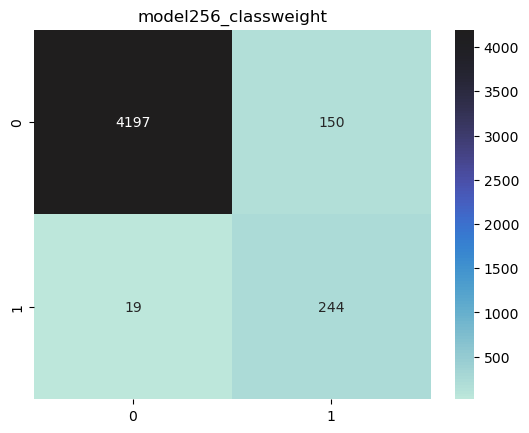

In [4]:
model256_classweight = keras.models.load_model('./trained_models/model256_classweight')
filtered_data, TP, FP, TN, FN, f1 = test_model(model256_classweight, test_ds)
print(f'f1-score: {f1}')

array = [[TN, FP],
        [FN, TP]]

df_cm = pd.DataFrame(array, range(2), range(2))
sn.heatmap(df_cm, annot=True, center=TN, fmt='g')
plt.title('model256_classweight')

plt.savefig('./documentation/model256_classweight.png')
plt.show()

In [6]:
model.save('./trained_models/model256_test')
model.summary()

INFO:tensorflow:Assets written to: ./trained_models/model256_test\assets


INFO:tensorflow:Assets written to: ./trained_models/model256_test\assets


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 256, 256, 8)       224       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 128, 128, 8)      0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 128, 128, 16)      1168      
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 64, 64, 16)       0         
 2D)                                                             
                                                                 
 conv2d_2 (Conv2D)           (None, 64, 64, 32)        4640      
                                                                 
 max_pooling2d_2 (MaxPooling  (None, 32, 32, 32)       0

In [3]:
model256 = keras.models.load_model('./trained_models/model256')
model256.summary()

Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_15 (Conv2D)          (None, 128, 128, 32)      4736      
                                                                 
 max_pooling2d_8 (MaxPooling  (None, 64, 64, 32)       0         
 2D)                                                             
                                                                 
 conv2d_16 (Conv2D)          (None, 32, 32, 64)        18496     
                                                                 
 conv2d_17 (Conv2D)          (None, 32, 32, 64)        36928     
                                                                 
 max_pooling2d_9 (MaxPooling  (None, 16, 16, 64)       0         
 2D)                                                             
                                                                 
 conv2d_18 (Conv2D)          (None, 8, 8, 128)        

f1-score: 0.84


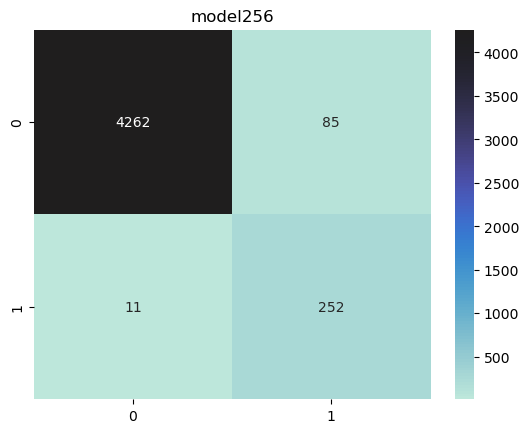

In [7]:
filtered_data, TP, FP, TN, FN, f1 = test_model(model256, test_ds)
print(f'f1-score: {f1}')

array = [[TN, FP],
        [FN, TP]]

df_cm = pd.DataFrame(array, range(2), range(2))
sn.heatmap(df_cm, annot=True, center=TN, fmt='g')
plt.title('model256')

plt.show()